# 5단계 최소 베이스라인 모델

이 노트북은 발표의 보조 자료로, 복잡한 예측 모델이 아니라 최소 베이스라인만 평가한다. 목표는 각 `reward_norm`의 다음 등장 간격을 과거 재등장 주기의 중앙값으로 예측했을 때 어느 정도 오차가 나는지 확인하는 것이다.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

project_root = Path.cwd()
if project_root.name == 'notebooks':
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.viz import save_fig, set_korean_font

set_korean_font()
RANDOM_SEED = 42

processed_path = project_root / 'data' / 'processed' / 'tidy_rewards.csv'
figure_dir = project_root / 'outputs' / 'figures'
tidy = pd.read_csv(processed_path, encoding='utf-8')
tidy['date'] = pd.to_datetime(tidy['date'])
analysis = tidy[tidy['reward_norm'].notna() & (~tidy['is_future'])].copy()

print('기본 분석 대상 행 수:', len(analysis))
print('난수 시드:', RANDOM_SEED)

기본 분석 대상 행 수: 1118
난수 시드: 42


## 평가 방법

등장일이 3회 이상인 `reward_norm`만 사용한다. 각 보상의 마지막 재등장 간격을 검증용 실제값으로 두고, 그 이전 `cycle_days` 중앙값을 예측값으로 사용한다.

In [2]:
unique_days = (
    analysis[['date', 'reward_norm', 'cycle_days']]
    .drop_duplicates(['date', 'reward_norm'])
    .sort_values(['reward_norm', 'date'])
)
counts = unique_days.groupby('reward_norm').size()
eligible_norms = counts[counts >= 3].index

global_median = unique_days['cycle_days'].dropna().median()
rows = []
for reward_norm, group in unique_days[unique_days['reward_norm'].isin(eligible_norms)].groupby('reward_norm'):
    history = group.dropna(subset=['cycle_days']).sort_values('date')
    if len(history) < 2:
        continue
    actual = float(history.iloc[-1]['cycle_days'])
    predicted = float(history.iloc[:-1]['cycle_days'].median())
    naive = float(global_median)
    rows.append({
        'reward_norm': reward_norm,
        '예측값': predicted,
        '실제값': actual,
        '전역 중앙값 예측': naive,
        '절대오차': abs(predicted - actual),
        '전역 중앙값 절대오차': abs(naive - actual),
        '학습 간격 수': len(history) - 1,
    })

model_result = pd.DataFrame(rows).sort_values('절대오차').reset_index(drop=True)
mae_baseline = model_result['절대오차'].mean()
mae_naive = model_result['전역 중앙값 절대오차'].mean()
summary = pd.DataFrame([
    {'모델': '보상별 과거 중앙값', '평균절대오차(일)': mae_baseline, '평가 보상 수': len(model_result)},
    {'모델': '전역 중앙값 기준', '평균절대오차(일)': mae_naive, '평가 보상 수': len(model_result)},
])

print('등장 3회 이상 reward_norm 수:', len(eligible_norms))
print('평가 대상 reward_norm 수:', len(model_result))
print('전역 cycle_days 중앙값:', global_median)
print('모델 비교:')
print(summary.round(2).to_string(index=False))
print('오차가 작은 예시:')
print(model_result.head(10).round(1).to_string(index=False))

등장 3회 이상 reward_norm 수: 34
평가 대상 reward_norm 수: 34
전역 cycle_days 중앙값: 42.0
모델 비교:
        모델  평균절대오차(일)  평가 보상 수
보상별 과거 중앙값      74.49       34
 전역 중앙값 기준      93.65       34
오차가 작은 예시:
reward_norm  예측값  실제값  전역 중앙값 예측  절대오차  전역 중앙값 절대오차  학습 간격 수
   경험치쿠폰_지급 63.0 56.0       42.0   7.0         14.0       18
    룬_경험치버프 28.0 35.0       42.0   7.0          7.0       86
    룬_재등장감소 28.0 35.0       42.0   7.0          7.0       21
  몬스터파크_경험치 21.0 14.0       42.0   7.0         28.0       80
   위대한소울_확률 63.0 70.0       42.0   7.0         28.0       51
 어빌리티_재설정할인 42.0 35.0       42.0   7.0          7.0       67
  스타포스_파괴방지 28.0 35.0       42.0   7.0          7.0       14
  스타포스_비용할인 42.0 35.0       42.0   7.0          7.0       71
    콤보킬_경험치 28.0 35.0       42.0   7.0          7.0       85
  흔적복구_비용할인 28.0 35.0       42.0   7.0          7.0        1


## 예측값과 실제값 비교

Figure saved: C:\Users\my\Desktop\프로젝트\sunday-maple\outputs\figures\model_pred_vs_actual.png
Actual values outside view: 2
Predicted values outside view: 0


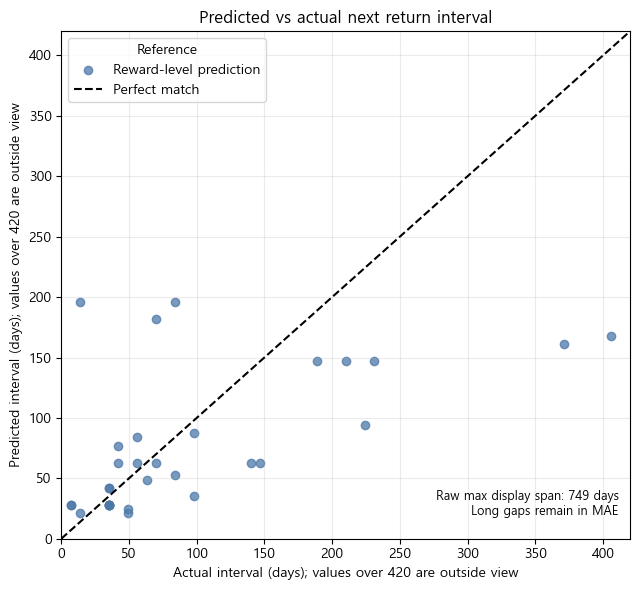

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 6))
pred_col = model_result.columns[1]
actual_col = model_result.columns[2]
ax.scatter(model_result[actual_col], model_result[pred_col], alpha=0.75, color='#4C78A8', label='Reward-level prediction')
limit = max(model_result[actual_col].max(), model_result[pred_col].max()) * 1.05
plot_limit = 420
ax.plot([0, plot_limit], [0, plot_limit], color='black', linestyle='--', label='Perfect match')
ax.set_title('Predicted vs actual next return interval')
ax.set_xlabel('Actual interval (days); values over 420 are outside view')
ax.set_ylabel('Predicted interval (days); values over 420 are outside view')
ax.set_xlim(0, plot_limit)
ax.set_ylim(0, plot_limit)
ax.text(0.98, 0.04, f'Raw max display span: {limit:.0f} days\nLong gaps remain in MAE', transform=ax.transAxes, ha='right', va='bottom', fontsize=9)
ax.legend(title='Reference')
ax.grid(True, alpha=0.25)
fig.tight_layout()
path = save_fig(fig, 'model_pred_vs_actual', figure_dir)
print('Figure saved:', path)
print('Actual values outside view:', int((model_result[actual_col] > plot_limit).sum()))
print('Predicted values outside view:', int((model_result[pred_col] > plot_limit).sum()))
plt.show()


보상별 과거 중앙값 베이스라인은 전역 중앙값만 쓰는 기준과 비교해 보상별 반복 주기를 일부 반영한다. 다만 이벤트 운영 정책 변화와 장기 휴면 보상을 설명하는 추가 피처는 넣지 않았으므로, 이 결과는 발표용 보조 기준선으로만 해석한다.